In [ ]:
IPL Cricket Analytics — Deliverable 1
Data Collection, Cleaning, and Exploration
Course: MSCS 634 — Advanced Big Data and Data Mining
Project: IPL Cricket Analytics: Data Cleaning, Exploratory Analysis, and Future Predictive Modeling

Scope: This notebook performs data selection, inspection, cleaning, EDA, and interpretation. No predictive models are trained in this deliverable.
Source and provenance
- Kaggle: https://www.kaggle.com/datasets/dgsports/ipl-ball-by-ball-2008-to-2022 (page title indicates 2008–2025; confirm actual coverage after download).
- Dataset description: https://github.com/SahilGogna/IPL-Hackathon/blob/main/DATA.md
- Data originally attributed to Cricsheet by the dataset guide.

In [ ]:
1. Dataset selection and research questions
The dataset consists of match-level records (one row per IPL match) and ball-by-ball delivery events (one row per recorded delivery). It exceeds the assignment's minimum requirement of 500 records and 8–10 attributes; the notebook verifies actual size below.

Questions: Which teams win most often? How do wins vary by season? How is toss winning associated with winning the match? Who are the leading run scorers? What are the run patterns by over phase? How do team innings scores vary, and are there unusually low/high scores?

Limitations: Historic results are descriptive, not causal. Team names and franchise histories change. Some matches lack a winner, and shortened innings can create legitimate low totals.    

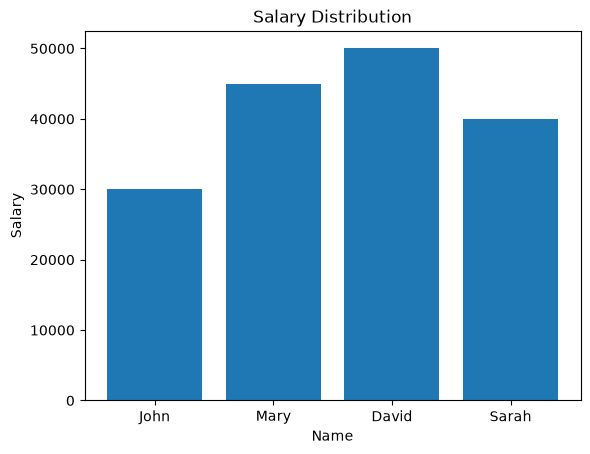

In [6]:
import numpy as np
import matplotlib.pyplot as plt

data = {
    "Name": ["John", "Mary", "David", "Sarah"],
    "Age": [25, 30, 35, 28],
    "Salary": [30000, 45000, 50000, 40000]
}

plt.bar(data["Name"], data["Salary"])
plt.xlabel("Name")
plt.ylabel("Salary")
plt.title("Salary Distribution")
plt.show()

In [4]:
import importlib.util

packages = ["numpy", "pandas", "matplotlib", "seaborn", "polars"]

for package in packages:
    print(package, importlib.util.find_spec(package) is not None)

numpy True
pandas False
matplotlib True
seaborn False
polars False


In [2]:
import sys
import platform

print("Python version:", sys.version)
print("Platform:", platform.platform())
print("Python executable:", sys.executable)

Python version: 3.13.1 (main, Feb 18 2026, 20:57:27) [Clang 21.0.0git (https:/github.com/llvm/llvm-project 2f05451198e2f222ec66cec489
Platform: Emscripten-4.0.9-wasm32-32bit
Python executable: 


In [9]:
import importlib.util

print("micropip:", importlib.util.find_spec("micropip"))
print("pandas:", importlib.util.find_spec("pandas"))
print("mamba:", importlib.util.find_spec("mamba"))

micropip: None
pandas: None
mamba: None


In [13]:
import sys
print(sys.platform)
print(sys.version)
print(sys.prefix)

emscripten
3.13.1 (main, Feb 18 2026, 20:57:27) [Clang 21.0.0git (https:/github.com/llvm/llvm-project 2f05451198e2f222ec66cec489
/


In [1]:
!mamba install -c emscripten-forge-4x pandas

mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 0.767 seconds
  Name    Version  Build                Channel
-------------------------------------------------------------
+ pandas  3.1.0    np23py313h124dbc7_0  emscripten-forge-4x
- pip     26.2.2   pyh145f28c_0         conda-forge


In [4]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

# Set visualization style
plt.style.use("ggplot")
plt.rcParams.update({
    "figure.figsize": (10, 5),
    "figure.dpi": 110
})

# Create folder for saving EDA charts
IMG_DIR = Path("screenshots")
IMG_DIR.mkdir(parents=True, exist_ok=True)

# IPL dataset URLs (GitHub)
BASE_URL = (
    "https://raw.githubusercontent.com/"
    "elavarasan-ai/IPL-Data-Analysis/main/"
)

matches_url = BASE_URL + "matches.csv"
deliveries_url = BASE_URL + "deliveries.csv"

# Load datasets directly from URLs
try:
    matches_raw = pd.read_csv(matches_url)
    deliveries_raw = pd.read_csv(deliveries_url)

    print("IPL datasets loaded successfully!\n")

except Exception as e:
    print("Error loading IPL datasets:", e)
    raise

# Display dataset information
print("Match records:", matches_raw.shape)
print("Ball-by-ball records:", deliveries_raw.shape)

print("\nMatch columns:")
print(matches_raw.columns.tolist())

print("\nDelivery columns:")
print(deliveries_raw.columns.tolist())

# Preview datasets
print("\nMatches Dataset Preview:")
display(matches_raw.head())

print("\nDeliveries Dataset Preview:")
display(deliveries_raw.head())

IPL datasets loaded successfully!

Match records: (1095, 20)
Ball-by-ball records: (260920, 17)

Match columns:
['id', 'season', 'city', 'date', 'match_type', 'player_of_match', 'venue', 'team1', 'team2', 'toss_winner', 'toss_decision', 'winner', 'result', 'result_margin', 'target_runs', 'target_overs', 'super_over', 'method', 'umpire1', 'umpire2']

Delivery columns:
['match_id', 'inning', 'batting_team', 'bowling_team', 'over', 'ball', 'batter', 'bowler', 'non_striker', 'batsman_runs', 'extra_runs', 'total_runs', 'extras_type', 'is_wicket', 'player_dismissed', 'dismissal_kind', 'fielder']

Matches Dataset Preview:


,id,season,city,date,match_type,player_of_match,venue,team1,team2,toss_winner,toss_decision,winner,result,result_margin,target_runs,target_overs,super_over,method,umpire1,umpire2
0,335982,2007/08,Bangalore,2008-04-18,League,BB McCullum,M Chinnaswamy Stadium,Royal Challengers Bangalore,Kolkata Knight Riders,Royal Challengers Bangalore,field,Kolkata Knight Riders,runs,140.0,223.0,20.0,N,NaN,Asad Rauf,RE Koertzen
1,335983,2007/08,Chandigarh,2008-04-19,League,MEK Hussey,"Punjab Cricket Association Stadium, Mohali",Kings XI Punjab,Chennai Super Kings,Chennai Super Kings,bat,Chennai Super Kings,runs,33.0,241.0,20.0,N,NaN,MR Benson,SL Shastri
2,335984,2007/08,Delhi,2008-04-19,League,MF Maharoof,Feroz Shah Kotla,Delhi Daredevils,Rajasthan Royals,Rajasthan Royals,bat,Delhi Daredevils,wickets,9.0,130.0,20.0,N,NaN,Aleem Dar,GA Pratapkumar
3,335985,2007/08,Mumbai,2008-04-20,League,MV Boucher,Wankhede Stadium,Mumbai Indians,Royal Challengers Bangalore,Mumbai Indians,bat,Royal Challengers Bangalore,wickets,5.0,166.0,20.0,N,NaN,SJ Davis,DJ Harper
4,335986,2007/08,Kolkata,2008-04-20,League,DJ Hussey,Eden Gardens,Kolkata Knight Riders,Deccan Chargers,Deccan Chargers,bat,Kolkata Knight Riders,wickets,5.0,111.0,20.0,N,NaN,BF Bowden,K Hariharan



Deliveries Dataset Preview:


,match_id,inning,batting_team,bowling_team,over,ball,batter,bowler,non_striker,batsman_runs,extra_runs,total_runs,extras_type,is_wicket,player_dismissed,dismissal_kind,fielder
0,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,1,SC Ganguly,P Kumar,BB McCullum,0,1,1,legbyes,0,NaN,NaN,NaN
1,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,2,BB McCullum,P Kumar,SC Ganguly,0,0,0,NaN,0,NaN,NaN,NaN
2,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,3,BB McCullum,P Kumar,SC Ganguly,0,1,1,wides,0,NaN,NaN,NaN
3,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,4,BB McCullum,P Kumar,SC Ganguly,0,0,0,NaN,0,NaN,NaN,NaN
4,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,5,BB McCullum,P Kumar,SC Ganguly,0,0,0,NaN,0,NaN,NaN,NaN


In [6]:
matches = matches_raw.copy()
deliveries = deliveries_raw.copy()

# Harmonize commonly used field names across public IPL dataset versions.
def rename_known(df, mapping):
    return df.rename(columns={k: v for k, v in mapping.items() if k in df.columns and v not in df.columns})

matches = rename_known(matches, {"id": "match_id", "winner": "match_won_by", "year": "season", "player_of_match": "player_of_match"})
deliveries = rename_known(deliveries, {"id": "match_id", "inning": "innings", "batsman": "batter",
                                        "batsman_runs": "runs_batter", "extra_runs": "runs_extras",
                                        "total_runs": "runs_total", "player_dismissed": "player_out",
                                        "dismissal_kind": "wicket_kind"})

for df in [matches, deliveries]:
    for col in df.select_dtypes(include=["object", "str"]).columns:
        df[col] = df[col].astype("string").str.strip().replace("", pd.NA)

# Team aliases: retain all team identities except known *name changes*.
team_aliases = {
    "Delhi Daredevils": "Delhi Capitals",
    "Kings XI Punjab": "Punjab Kings",
    "Royal Challengers Bangalore": "Royal Challengers Bengaluru",
}
for df in [matches, deliveries]:
    for col in ["team1", "team2", "toss_winner", "match_won_by", "batting_team", "bowling_team"]:
        if col in df:
            df[col] = df[col].replace(team_aliases)

required_matches = ["match_id", "team1", "team2", "toss_winner", "match_won_by"]
required_deliveries = ["match_id", "innings", "over", "batter", "runs_batter", "runs_total"]
for label, df, needed in [("matches", matches, required_matches), ("deliveries", deliveries, required_deliveries)]:
    missing_cols = [col for col in needed if col not in df.columns]
    if missing_cols:
        raise ValueError(f"{label} missing required columns {missing_cols}; review printed column names and adapt the aliases.")

for col in ["match_id"]:
    matches[col] = pd.to_numeric(matches[col], errors="coerce")
    deliveries[col] = pd.to_numeric(deliveries[col], errors="coerce")
for col in ["innings", "over", "runs_batter", "runs_total", "runs_extras", "ball"]:
    if col in deliveries:
        deliveries[col] = pd.to_numeric(deliveries[col], errors="coerce")
if "date" in matches:
    matches["date"] = pd.to_datetime(matches["date"], errors="coerce")
if "season" not in matches and "date" in matches:
    matches["season"] = matches["date"].dt.year

print("Invalid match IDs:", matches.match_id.isna().sum(), deliveries.match_id.isna().sum())
print("Duplicate match IDs:", matches.match_id.duplicated().sum())
print("Exact duplicate delivery rows (review before removing):", deliveries.duplicated().sum())
print("Missing match winners (often no-result/tied matches):", matches.match_won_by.isna().sum())
print("Invalid date conversions:", matches["date"].isna().sum() if "date" in matches else "no date column")

Invalid match IDs: 0 0
Duplicate match IDs: 0
Exact duplicate delivery rows (review before removing): 0
Missing match winners (often no-result/tied matches): 5
Invalid date conversions: 0


In [ ]:
Initial Dataset Inspection: 
Document shape, sample rows, variable types, missing values, numerical summaries, categorical values, and the time period covered. 
Record the actual row and column counts in the README after executing this section.

In [7]:
display(matches_raw.head())
display(deliveries_raw.head())
print("Match dtypes:")
print(matches_raw.dtypes.to_string())
print("Delivery dtypes:")
print(deliveries_raw.dtypes.to_string())
display(matches_raw.describe(include="all").T.head(30))
display(deliveries_raw.describe(include="all").T.head(30))

missing_matches = pd.DataFrame({"missing": matches_raw.isna().sum(),
                                "percent": matches_raw.isna().mean() * 100}).sort_values("percent", ascending=False)
missing_deliveries = pd.DataFrame({"missing": deliveries_raw.isna().sum(),
                                   "percent": deliveries_raw.isna().mean() * 100}).sort_values("percent", ascending=False)
print("Missing values in matches:")
display(missing_matches.head(25))
print("Missing values in deliveries:")
display(missing_deliveries.head(25))
print("Fully duplicated rows (raw):", matches_raw.duplicated().sum(), deliveries_raw.duplicated().sum())

,id,season,city,date,match_type,player_of_match,venue,team1,team2,toss_winner,toss_decision,winner,result,result_margin,target_runs,target_overs,super_over,method,umpire1,umpire2
0,335982,2007/08,Bangalore,2008-04-18,League,BB McCullum,M Chinnaswamy Stadium,Royal Challengers Bangalore,Kolkata Knight Riders,Royal Challengers Bangalore,field,Kolkata Knight Riders,runs,140.0,223.0,20.0,N,NaN,Asad Rauf,RE Koertzen
1,335983,2007/08,Chandigarh,2008-04-19,League,MEK Hussey,"Punjab Cricket Association Stadium, Mohali",Kings XI Punjab,Chennai Super Kings,Chennai Super Kings,bat,Chennai Super Kings,runs,33.0,241.0,20.0,N,NaN,MR Benson,SL Shastri
2,335984,2007/08,Delhi,2008-04-19,League,MF Maharoof,Feroz Shah Kotla,Delhi Daredevils,Rajasthan Royals,Rajasthan Royals,bat,Delhi Daredevils,wickets,9.0,130.0,20.0,N,NaN,Aleem Dar,GA Pratapkumar
3,335985,2007/08,Mumbai,2008-04-20,League,MV Boucher,Wankhede Stadium,Mumbai Indians,Royal Challengers Bangalore,Mumbai Indians,bat,Royal Challengers Bangalore,wickets,5.0,166.0,20.0,N,NaN,SJ Davis,DJ Harper
4,335986,2007/08,Kolkata,2008-04-20,League,DJ Hussey,Eden Gardens,Kolkata Knight Riders,Deccan Chargers,Deccan Chargers,bat,Kolkata Knight Riders,wickets,5.0,111.0,20.0,N,NaN,BF Bowden,K Hariharan


,match_id,inning,batting_team,bowling_team,over,ball,batter,bowler,non_striker,batsman_runs,extra_runs,total_runs,extras_type,is_wicket,player_dismissed,dismissal_kind,fielder
0,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,1,SC Ganguly,P Kumar,BB McCullum,0,1,1,legbyes,0,NaN,NaN,NaN
1,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,2,BB McCullum,P Kumar,SC Ganguly,0,0,0,NaN,0,NaN,NaN,NaN
2,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,3,BB McCullum,P Kumar,SC Ganguly,0,1,1,wides,0,NaN,NaN,NaN
3,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,4,BB McCullum,P Kumar,SC Ganguly,0,0,0,NaN,0,NaN,NaN,NaN
4,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,5,BB McCullum,P Kumar,SC Ganguly,0,0,0,NaN,0,NaN,NaN,NaN


Match dtypes:
id                   int64
season                 str
city                   str
date                   str
match_type             str
player_of_match        str
venue                  str
team1                  str
team2                  str
toss_winner            str
toss_decision          str
winner                 str
result                 str
result_margin      float64
target_runs        float64
target_overs       float64
super_over             str
method                 str
umpire1                str
umpire2                str
Delivery dtypes:
match_id            int64
inning              int64
batting_team          str
bowling_team          str
over                int64
ball                int64
batter                str
bowler                str
non_striker           str
batsman_runs        int64
extra_runs          int64
total_runs          int64
extras_type           str
is_wicket           int64
player_dismissed      str
dismissal_kind        str
fielder      

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,1095.0,NaN,NaN,NaN,904828.319635,367740.242299,335982.0,548331.5,980961.0,1254062.5,1426312.0
season,1095,17,2013,76,NaN,NaN,NaN,NaN,NaN,NaN,NaN
city,1044,36,Mumbai,173,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date,1095,823,2008-04-19,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
match_type,1095,8,League,1029,NaN,NaN,NaN,NaN,NaN,NaN,NaN
player_of_match,1090,291,AB de Villiers,25,NaN,NaN,NaN,NaN,NaN,NaN,NaN
venue,1095,58,Eden Gardens,77,NaN,NaN,NaN,NaN,NaN,NaN,NaN
team1,1095,19,Royal Challengers Bangalore,135,NaN,NaN,NaN,NaN,NaN,NaN,NaN
team2,1095,19,Mumbai Indians,138,NaN,NaN,NaN,NaN,NaN,NaN,NaN
toss_winner,1095,19,Mumbai Indians,143,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
match_id,260920.0,NaN,NaN,NaN,907066.506086,367991.278255,335982.0,548334.0,980967.0,1254066.0,1426312.0
inning,260920.0,NaN,NaN,NaN,1.483531,0.502643,1.0,1.0,1.0,2.0,6.0
batting_team,260920,19,Mumbai Indians,31437,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bowling_team,260920,19,Mumbai Indians,31505,NaN,NaN,NaN,NaN,NaN,NaN,NaN
over,260920.0,NaN,NaN,NaN,9.197677,5.683484,0.0,4.0,9.0,14.0,19.0
ball,260920.0,NaN,NaN,NaN,3.624486,1.81492,1.0,2.0,4.0,5.0,11.0
batter,260920,673,V Kohli,6236,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bowler,260920,530,R Ashwin,4679,NaN,NaN,NaN,NaN,NaN,NaN,NaN
non_striker,260920,663,V Kohli,6067,NaN,NaN,NaN,NaN,NaN,NaN,NaN
batsman_runs,260920.0,NaN,NaN,NaN,1.265001,1.639298,0.0,0.0,1.0,1.0,6.0


Missing values in matches:


,missing,percent
method,1074,98.082192
city,51,4.657534
result_margin,19,1.735160
winner,5,0.456621
player_of_match,5,0.456621
target_overs,3,0.273973
target_runs,3,0.273973
id,0,0.000000
umpire1,0,0.000000
super_over,0,0.000000


Missing values in deliveries:


,missing,percent
fielder,251566,96.414993
dismissal_kind,247970,95.036793
player_dismissed,247970,95.036793
extras_type,246795,94.586463
batsman_runs,0,0.000000
is_wicket,0,0.000000
total_runs,0,0.000000
extra_runs,0,0.000000
match_id,0,0.000000
inning,0,0.000000


Fully duplicated rows (raw): 0 0


In [ ]:
2. Cleaning and quality checks
Important decisions:
1. Preserve the original frames as matches_raw / deliveries_raw and work on copies.
2. Normalize leading/trailing whitespace and blank strings.
3. Normalize known historical team name aliases for consistent grouping, without assuming franchises are historically identical. These mappings are for this exploratory analysis only.
4. Convert dates, IDs, and numeric measures where applicable. Investigate conversion failures before dropping rows.
5. Treat missing player_out, wicket_kind, and similar dismissal/extra fields as structural missingness: most balls are not wickets, so blanket dropna() is incorrect.
6. Check exact duplicates. Do not automatically drop delivery rows: otherwise valid repeated events might be discarded if identifiers are absent.
7. Validate run totals and check for mismatched match IDs or suspicious negative values.

In [9]:

matches = matches_raw.copy()
deliveries = deliveries_raw.copy()

# Harmonize commonly used field names
def rename_known(df, mapping):
    return df.rename(
        columns={
            k: v for k, v in mapping.items()
            if k in df.columns and v not in df.columns
        }
    )

matches = rename_known(matches, {
    "id": "match_id",
    "winner": "match_won_by",
    "year": "season"
})

deliveries = rename_known(deliveries, {
    "id": "match_id",
    "inning": "innings",
    "batsman": "batter",
    "batsman_runs": "runs_batter",
    "extra_runs": "runs_extras",
    "total_runs": "runs_total",
    "player_dismissed": "player_out",
    "dismissal_kind": "wicket_kind"
})

# Clean text columns
for df in [matches, deliveries]:
    for col in df.select_dtypes(include=["object", "str"]).columns:
        df[col] = (
            df[col]
            .astype("string")
            .str.strip()
            .replace("", pd.NA)
        )

# Standardize team names
team_aliases = {
    "Delhi Daredevils": "Delhi Capitals",
    "Kings XI Punjab": "Punjab Kings",
    "Royal Challengers Bangalore": "Royal Challengers Bengaluru"
}

for df in [matches, deliveries]:
    for col in [
        "team1", "team2", "toss_winner",
        "match_won_by", "batting_team", "bowling_team"
    ]:
        if col in df.columns:
            df[col] = df[col].replace(team_aliases)

# Validate required columns
required_matches = [
    "match_id", "team1", "team2",
    "toss_winner", "match_won_by"
]

required_deliveries = [
    "match_id", "innings", "over",
    "batter", "runs_batter", "runs_total"
]

for label, df, needed in [
    ("matches", matches, required_matches),
    ("deliveries", deliveries, required_deliveries)
]:
    missing_cols = [
        col for col in needed if col not in df.columns
    ]

    if missing_cols:
        raise ValueError(
            f"{label} missing required columns: {missing_cols}"
        )

# Convert numeric columns
matches["match_id"] = pd.to_numeric(
    matches["match_id"], errors="coerce"
)

deliveries["match_id"] = pd.to_numeric(
    deliveries["match_id"], errors="coerce"
)

for col in [
    "innings", "over", "runs_batter",
    "runs_total", "runs_extras", "ball"
]:
    if col in deliveries.columns:
        deliveries[col] = pd.to_numeric(
            deliveries[col], errors="coerce"
        )

# Convert dates
if "date" in matches.columns:
    matches["date"] = pd.to_datetime(
        matches["date"], errors="coerce"
    )

if "season" not in matches.columns and "date" in matches.columns:
    matches["season"] = matches["date"].dt.year

# Data quality report
print("DATA QUALITY REPORT")
print("=" * 40)

print("Invalid match IDs:",
      matches["match_id"].isna().sum(),
      deliveries["match_id"].isna().sum())

print("Duplicate match IDs:",
      matches["match_id"].duplicated().sum())

print("Exact duplicate delivery rows:",
      deliveries.duplicated().sum())

print("Missing match winners:",
      matches["match_won_by"].isna().sum())

print("Invalid date conversions:",
      matches["date"].isna().sum()
      if "date" in matches.columns else "No date column")

print("\nData cleaning completed successfully!")


DATA QUALITY REPORT
Invalid match IDs: 0 0
Duplicate match IDs: 0
Exact duplicate delivery rows: 0
Missing match winners: 5
Invalid date conversions: 0

Data cleaning completed successfully!


In [ ]:
Validate data consistency, avoid indiscriminate deletion
Do not delete match_won_by missing records automatically; no-result matches can have missing winner. For match-winner plots, filter to records with a valid winner. Duplicate match IDs and delivery IDs require investigation; this notebook prints suspicious rows for review.

In [10]:
# Quality checks with explanatory outputs. Do not silently discard unexpected data.
print("Matches before cleaning:", len(matches_raw), "after:", len(matches))
print("Deliveries before cleaning:", len(deliveries_raw), "after:", len(deliveries))
print("Negative runs:", (deliveries.runs_total < 0).sum())
print("Invalid reported runs:", deliveries.runs_total.isna().sum())
print("Negative over indices:", (deliveries.over < 0).sum())
print("Unknown match IDs in deliveries:", (~deliveries.match_id.isin(matches.match_id)).sum())
print("Duplicate match ID examples:")
display(matches.loc[matches.match_id.duplicated(keep=False)].head(10))

if {"runs_batter", "runs_extras", "runs_total"}.issubset(deliveries):
    comparable = deliveries[["runs_batter", "runs_extras", "runs_total"]].dropna()
    mismatch = comparable["runs_batter"] + comparable["runs_extras"] != comparable["runs_total"]
    print("Rows where batter runs + extras != total:", mismatch.sum())

print("Missing values after type/label normalization (match top 12):")
display(matches.isna().sum().sort_values(ascending=False).head(12).to_frame("missing"))

# Standard innings only; special super-over entries are excluded from scoring comparisons.
standard_balls = deliveries[deliveries.innings.isin([1, 2])].copy()
# Keep rows with valid total runs for numerical calculations, but retain originals above.
standard_balls = standard_balls.dropna(subset=["match_id", "over", "runs_total", "runs_batter"])

print("Standard-innings delivery rows for EDA:", len(standard_balls))
print("Seasons:", matches.season.min() if "season" in matches else "unknown", "through",
      matches.season.max() if "season" in matches else "unknown")

Matches before cleaning: 1095 after: 1095
Deliveries before cleaning: 260920 after: 260920
Negative runs: 0
Invalid reported runs: 0
Negative over indices: 0
Unknown match IDs in deliveries: 0
Duplicate match ID examples:


,match_id,season,city,date,match_type,player_of_match,venue,team1,team2,toss_winner,toss_decision,match_won_by,result,result_margin,target_runs,target_overs,super_over,method,umpire1,umpire2


Rows where batter runs + extras != total: 0
Missing values after type/label normalization (match top 12):


,missing
method,1074
city,51
result_margin,19
match_won_by,5
player_of_match,5
target_overs,3
target_runs,3
match_id,0
umpire1,0
super_over,0


Standard-innings delivery rows for EDA: 260759
Seasons: 2007/08 through 2024


In [ ]:
3. Exploratory data analysis (EDA)
Each graph has labels, title, and a reproducible image saved to screenshots/. Interpret the actual output in the analysis notes after running; do not pre-fill numerical findings.


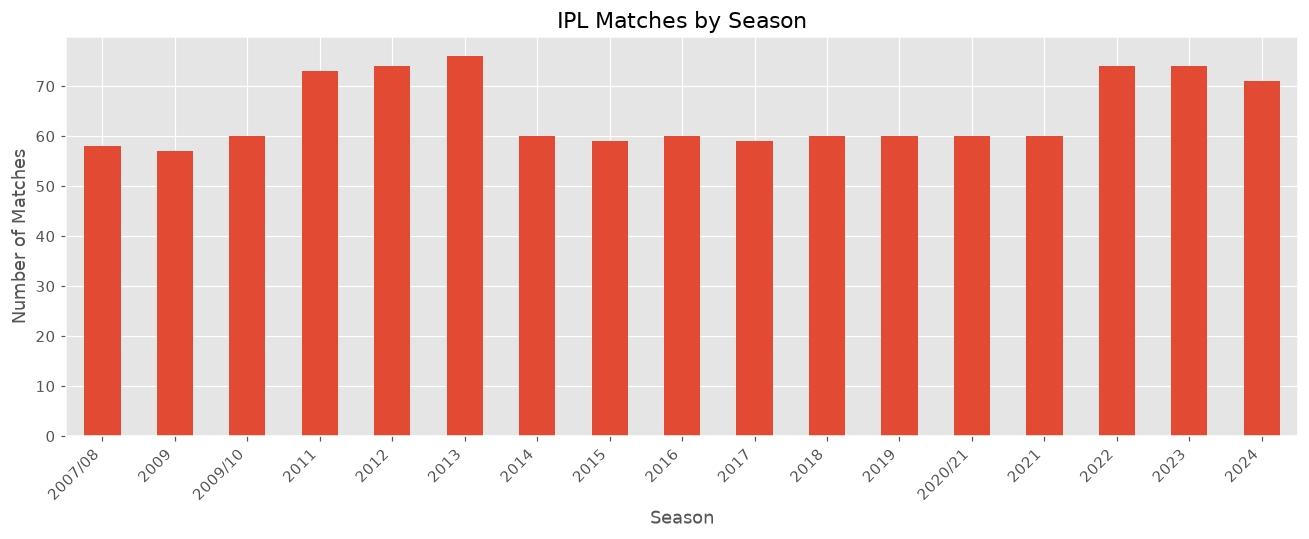

,matches
season,
2015,59
2016,60
2017,59
2018,60
2019,60
2020/21,60
2021,60
2022,74
2023,74


In [11]:
# Chart 1: matches per season
season_counts = matches.groupby("season", dropna=False).size().sort_index() 
plt.figure(figsize=(12, 5))
season_counts.plot(kind="bar")
plt.title("IPL Matches by Season")
plt.xlabel("Season")
plt.ylabel("Number of Matches")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(IMG_DIR / "01_matches_by_season.png", bbox_inches="tight")
plt.show()
display(season_counts.to_frame("matches").tail(10))

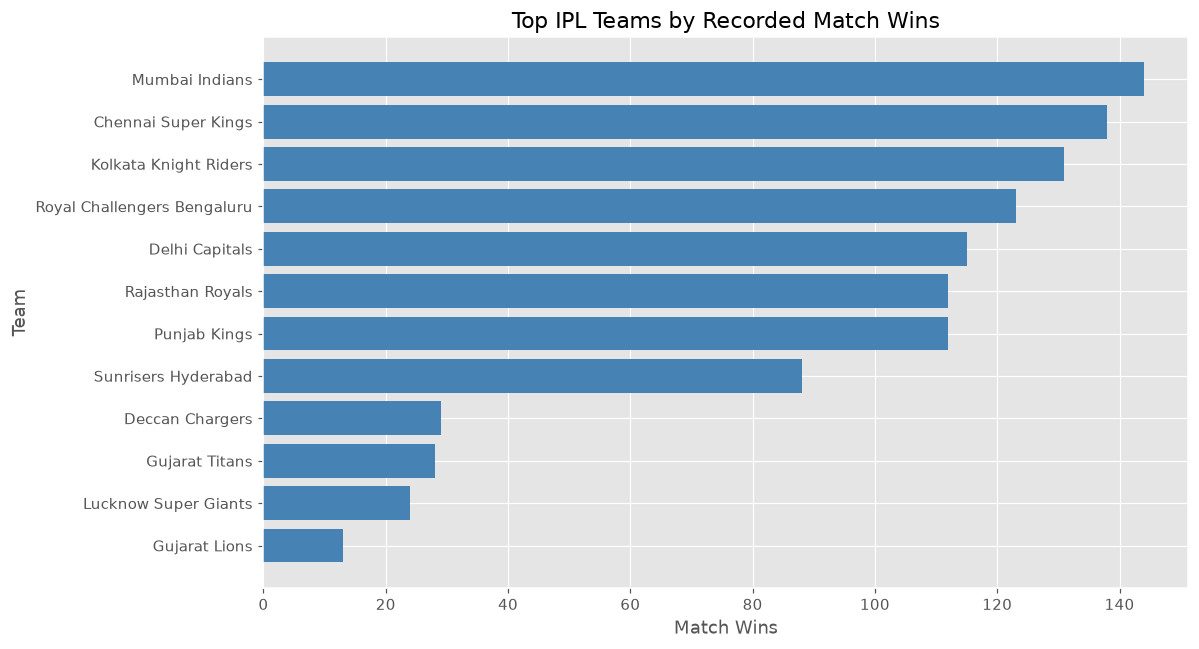

,wins
match_won_by,
Mumbai Indians,144
Chennai Super Kings,138
Kolkata Knight Riders,131
Royal Challengers Bengaluru,123
Delhi Capitals,115
Rajasthan Royals,112
Punjab Kings,112
Sunrisers Hyderabad,88
Deccan Chargers,29


In [13]:

# Chart 2: match wins by team (no-result matches omitted)

valid_winners = matches.dropna(subset=["match_won_by"])

wins = valid_winners["match_won_by"].value_counts().head(12)

plt.figure(figsize=(11, 6))

# Use Matplotlib instead of Seaborn
plt.barh(
    wins.index[::-1],
    wins.values[::-1],
    color="steelblue"
)

plt.title("Top IPL Teams by Recorded Match Wins")
plt.xlabel("Match Wins")
plt.ylabel("Team")

plt.tight_layout()

plt.savefig(
    IMG_DIR / "02_team_wins.png",
    bbox_inches="tight"
)

plt.show()

display(wins.to_frame("wins"))

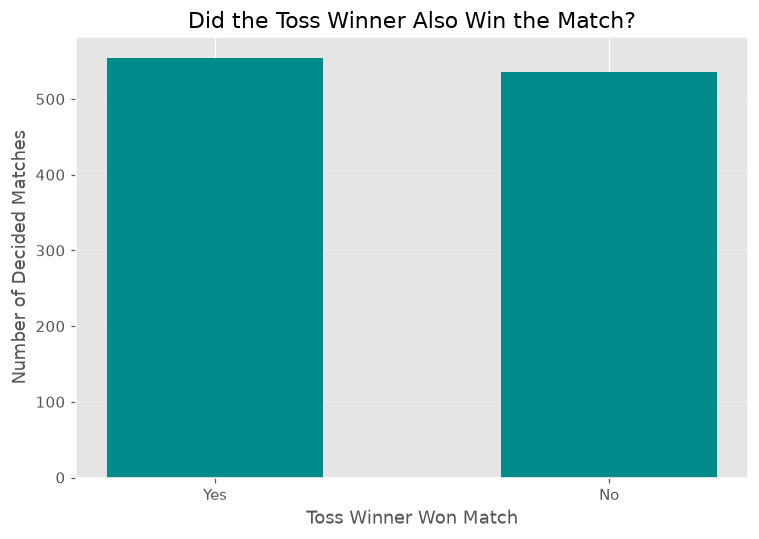

Toss winner won 554 of 1,090 decided matches (50.8%).


In [15]:

# Chart 3: Toss-win association with match-win outcomes
# Only matches with known winners included.

toss_df = matches.dropna(
    subset=["toss_winner", "match_won_by"]
).copy()

toss_df["toss_winner_won_match"] = (
    toss_df.toss_winner.eq(toss_df.match_won_by)
)

counts = (
    toss_df["toss_winner_won_match"]
    .value_counts()
    .reindex([True, False], fill_value=0)
)

plt.figure(figsize=(7, 5))

# Matplotlib instead of Seaborn
plt.bar(
    ["Yes", "No"],
    [counts[True], counts[False]],
    color="darkcyan",
    width=0.55
)

plt.title("Did the Toss Winner Also Win the Match?")
plt.xlabel("Toss Winner Won Match")
plt.ylabel("Number of Decided Matches")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    IMG_DIR / "03_toss_vs_win.png",
    bbox_inches="tight"
)

plt.show()

if len(toss_df):
    print(
        f"Toss winner won {counts[True]:,} "
        f"of {len(toss_df):,} decided matches "
        f"({100 * counts[True] / len(toss_df):.1f}%)."
    )
else:
    print("No decided matches available.")


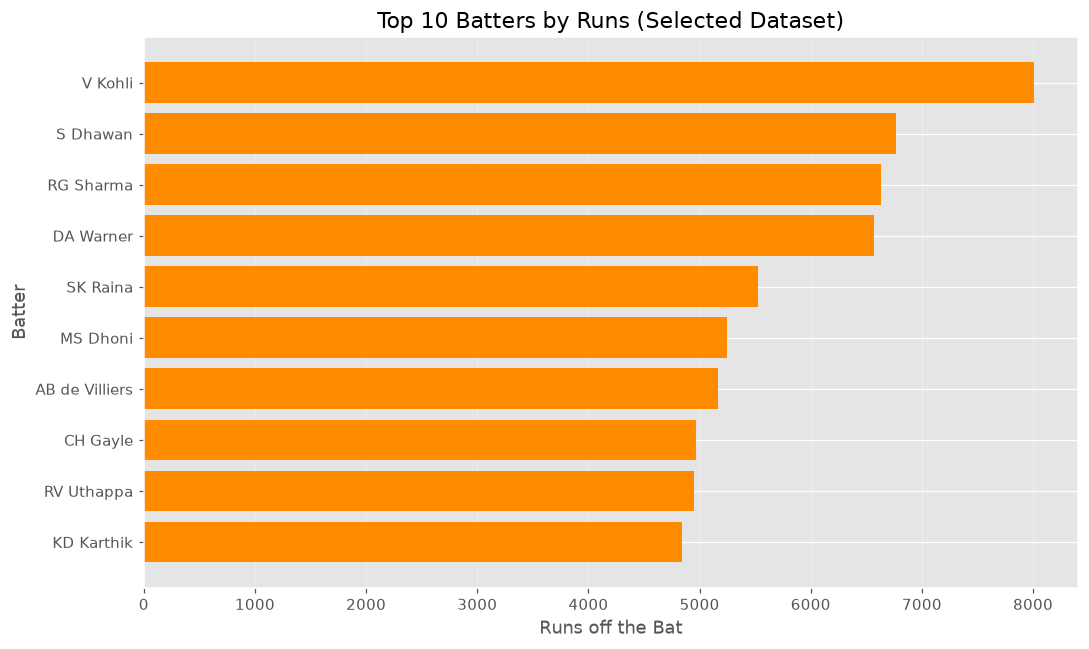

,runs
batter,
V Kohli,8004
S Dhawan,6769
RG Sharma,6628
DA Warner,6565
SK Raina,5528
MS Dhoni,5243
AB de Villiers,5162
CH Gayle,4965
RV Uthappa,4952


In [17]:

# Chart 4: Top IPL batters by runs scored off the bat

batting = (
    standard_balls.groupby("batter")["runs_batter"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(10, 6))

# Use Matplotlib instead of Seaborn
plt.barh(
    batting.index[::-1],
    batting.values[::-1],
    color="darkorange"
)

plt.title("Top 10 Batters by Runs (Selected Dataset)")
plt.xlabel("Runs off the Bat")
plt.ylabel("Batter")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

plt.savefig(
    IMG_DIR / "04_top_batters.png",
    bbox_inches="tight"
)

plt.show()

# Display top 10 batters
display(batting.to_frame("runs"))


Recorded over range: 0 to 19


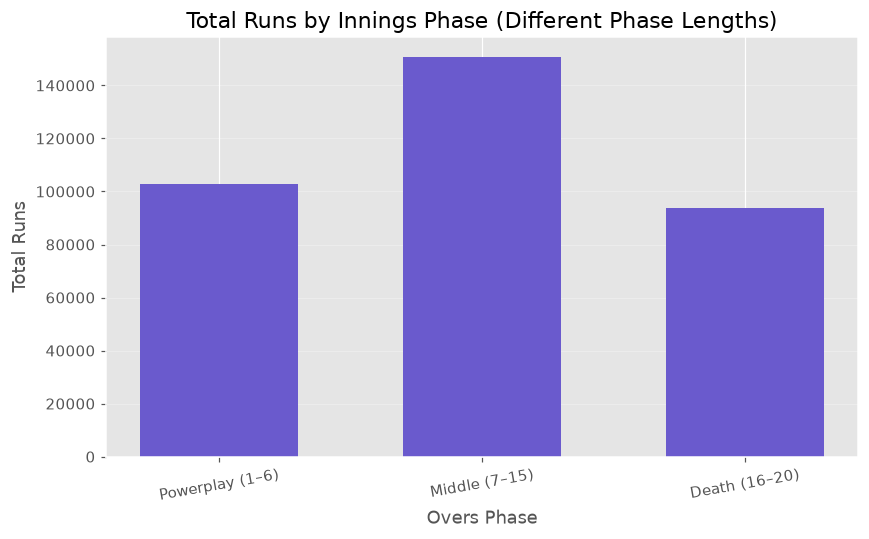

,runs
phase,
Powerplay (1–6),102931
Middle (7–15),150655
Death (16–20),93884


CAUTION: Phase totals are not directly comparable per over (phases have 6, 9, and 5 overs).


In [18]:

# Chart 5: Runs in each innings over phase

# Check over numbering
print(
    "Recorded over range:",
    standard_balls.over.min(),
    "to",
    standard_balls.over.max()
)

if standard_balls.over.min() == 0:
    phase_over = standard_balls.over
elif standard_balls.over.min() == 1:
    phase_over = standard_balls.over - 1
else:
    raise ValueError(
        "Unexpected over numbering; inspect the data before defining over phases."
    )

# Define innings phases
standard_balls["phase"] = pd.cut(
    phase_over,
    bins=[-1, 5, 14, 19],
    labels=[
        "Powerplay (1–6)",
        "Middle (7–15)",
        "Death (16–20)"
    ]
)

# Calculate total runs by phase
phase = (
    standard_balls.groupby("phase", observed=True)["runs_total"]
    .sum()
)

# Create chart using Matplotlib
plt.figure(figsize=(8, 5))

plt.bar(
    phase.index.astype(str),
    phase.values,
    color="slateblue",
    width=0.6
)

plt.title("Total Runs by Innings Phase (Different Phase Lengths)")
plt.xlabel("Overs Phase")
plt.ylabel("Total Runs")

plt.xticks(rotation=10)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    IMG_DIR / "05_runs_by_phase.png",
    bbox_inches="tight"
)

plt.show()

# Display results
display(phase.to_frame("runs"))

print(
    "CAUTION: Phase totals are not directly comparable per over "
    "(phases have 6, 9, and 5 overs)."
)


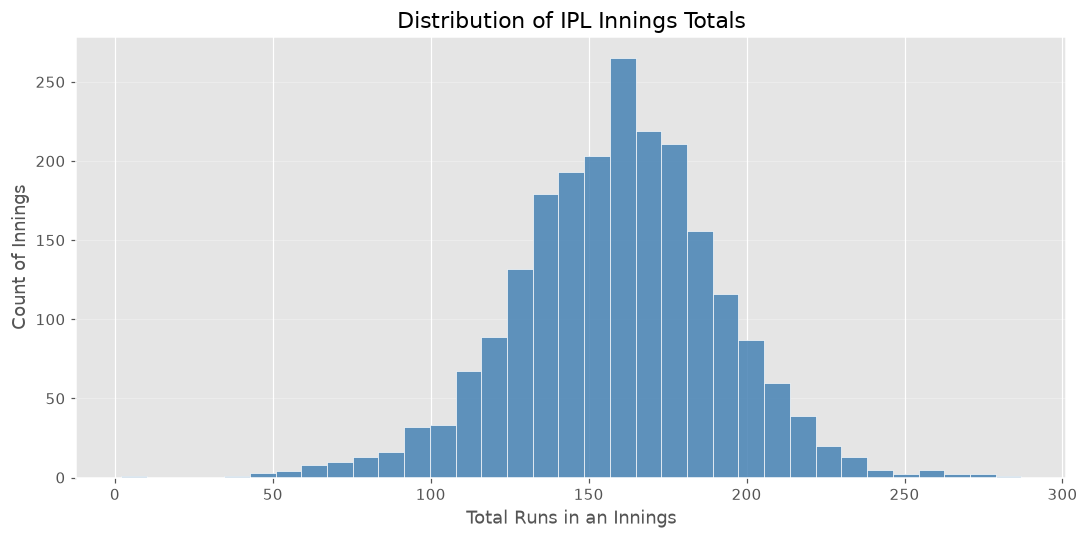

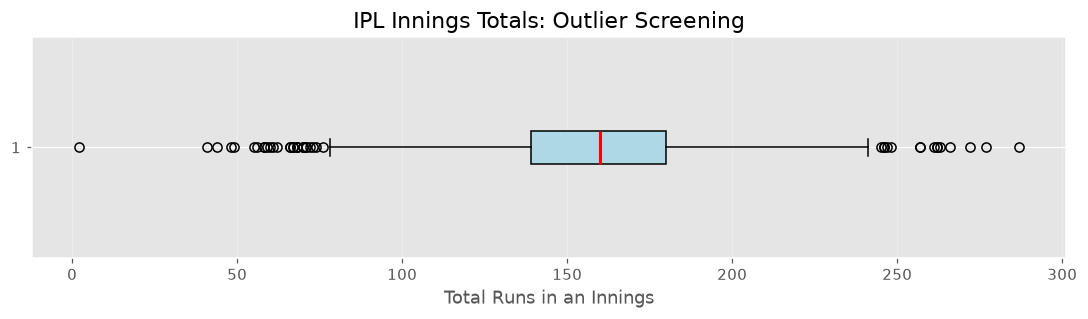

,total_runs
count,2187.000000
mean,158.879744
std,32.577021
min,2.000000
25%,139.000000
50%,160.000000
75%,180.000000
max,287.000000


In [21]:

# Chart 6: Distribution of standard innings totals

innings_scores = (
    standard_balls.groupby(
        ["match_id", "innings"], as_index=False
    )
    .agg(
        total_runs=("runs_total", "sum"),
        balls_recorded=("runs_total", "size")
    )
)

# Chart 6A: Histogram
plt.figure(figsize=(10, 5))

plt.hist(
    innings_scores["total_runs"].dropna(),
    bins=35,
    color="steelblue",
    edgecolor="white",
    alpha=0.85
)

plt.title("Distribution of IPL Innings Totals")
plt.xlabel("Total Runs in an Innings")
plt.ylabel("Count of Innings")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    IMG_DIR / "06_innings_score_distribution.png",
    bbox_inches="tight"
)

plt.show()


# Chart 6B: Boxplot
plt.figure(figsize=(10, 3))

plt.boxplot(
    innings_scores["total_runs"].dropna(),
    orientation="horizontal",
    patch_artist=True,
    boxprops=dict(facecolor="lightblue"),
    medianprops=dict(color="red", linewidth=2)
)

plt.title("IPL Innings Totals: Outlier Screening")
plt.xlabel("Total Runs in an Innings")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

plt.savefig(
    IMG_DIR / "07_innings_score_boxplot.png",
    bbox_inches="tight"
)

plt.show()


# Statistical summary
display(
    innings_scores["total_runs"]
    .describe()
    .to_frame("total_runs")
)

In [ ]:
Outlier analysis and context
The IQR rule flags possible extreme innings totals. Do not automatically remove extremes: totals may be genuine record scores, low scores after collapses, rain-shortened matches, incomplete innings, or special match circumstances. Review extreme matches against match metadata and document any exclusion criteria.

In [24]:
q1, q3 = innings_scores.total_runs.quantile([0.25, 0.75])
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
potential_outliers = innings_scores.loc[
    (innings_scores.total_runs < lower) | (innings_scores.total_runs > upper)
].sort_values("total_runs")
print(f"IQR bounds: {lower:.1f} to {upper:.1f}; flagged innings: {len(potential_outliers)}")
display(potential_outliers.head(10))
display(potential_outliers.tail(10))
# No automatic deletion of these flagged records.

IQR bounds: 77.5 to 241.5; flagged innings: 43


,match_id,innings,total_runs,balls_recorded
1021,829813,2,2,7
1487,1178424,2,41,20
858,733993,2,44,30
1265,1082648,2,48,35
1205,1082617,2,49,62
87,336025,2,55,51
482,501265,1,56,63
119,392182,2,58,99
121,392183,2,58,32
2016,1359534,2,59,65


,match_id,innings,total_runs,balls_recorded
1972,1359512,1,257,129
2129,1426281,1,257,127
2127,1426280,1,261,131
2104,1426268,2,262,133
2128,1426280,2,262,116
701,598027,1,263,128
2113,1426273,1,266,123
2075,1422134,1,272,134
2059,1422126,1,277,130
2103,1426268,1,287,132
